Installing dependencies

In [ ]:
pip install opencv-python matplotlib imageio gdown tensorflow

Note: you may need to restart the kernel to use updated packages.


Importing dependencies

In [51]:
import os
import cv2
import tensorflow as tf
import numpy as np
from typing import List
from matplotlib import pyplot as plt 
import imageio #This is used to convert list array to GIF

In [52]:
physical_devices = tf.config.list_physical_devices("GPU")
try:
    tf.config.experimental.set_memory_growth(physical_devices[0], True)
except:
    pass

Data loading 

In [53]:
import gdown

In [54]:
""""
url = 'https://drive.google.com/uc?id=1YlvpDLix3S-U8fd-gqRwPcWXAXm8JwjL'
output = 'data.zip'
gdown.download(url, output, quiet = False)
gdown.extractall('data.zip')"""

'"\nurl = \'https://drive.google.com/uc?id=1YlvpDLix3S-U8fd-gqRwPcWXAXm8JwjL\'\noutput = \'data.zip\'\ngdown.download(url, output, quiet = False)\ngdown.extractall(\'data.zip\')'

In [55]:
def load_video(path:str) -> List[float]:

    cap = cv2.VideoCapture(path)
    frames = []
    for _ in range (int(cap.get(cv2.CAP_PROP_FRAME_COUNT))):
        ret, frame = cap.read()
        frame = tf.image.rgb_to_grayscale(frame)
        frames.append(frame[190:236,80:220,:])
    cap.release()

    mean = tf.math.reduce_mean(frames)
    std = tf.math.reduce_std(tf.cast(frames, tf.float32))

    return tf.cast((frames-mean), tf.float32) / std


In [56]:
vocab = [x for x in "abcdefghijklmnopqrstuvwxyz'?!123456789 "]  #Creating a list of all possible values

In [57]:
vocab

['a',
 'b',
 'c',
 'd',
 'e',
 'f',
 'g',
 'h',
 'i',
 'j',
 'k',
 'l',
 'm',
 'n',
 'o',
 'p',
 'q',
 'r',
 's',
 't',
 'u',
 'v',
 'w',
 'x',
 'y',
 'z',
 "'",
 '?',
 '!',
 '1',
 '2',
 '3',
 '4',
 '5',
 '6',
 '7',
 '8',
 '9',
 ' ']

In [58]:
char_to_num = tf.keras.layers.StringLookup(vocabulary=vocab, oov_token="")
num_to_char = tf.keras.layers.StringLookup(vocabulary=char_to_num.get_vocabulary(),
                                           oov_token="", invert=True)

print(f"Vocabulary are : {char_to_num.get_vocabulary()}"
      f"Size = {char_to_num.vocabulary_size()}")

Vocabulary are : ['', np.str_('a'), np.str_('b'), np.str_('c'), np.str_('d'), np.str_('e'), np.str_('f'), np.str_('g'), np.str_('h'), np.str_('i'), np.str_('j'), np.str_('k'), np.str_('l'), np.str_('m'), np.str_('n'), np.str_('o'), np.str_('p'), np.str_('q'), np.str_('r'), np.str_('s'), np.str_('t'), np.str_('u'), np.str_('v'), np.str_('w'), np.str_('x'), np.str_('y'), np.str_('z'), np.str_("'"), np.str_('?'), np.str_('!'), np.str_('1'), np.str_('2'), np.str_('3'), np.str_('4'), np.str_('5'), np.str_('6'), np.str_('7'), np.str_('8'), np.str_('9'), np.str_(' ')]Size = 40


In [59]:
def load_alignments(path:str) -> List[str]:
    with open(path, 'r')as f:
        lines = f.readlines()
    tokens = []
    for line in lines:
        line = line.split()
        if line[2] != 'sil':
            tokens = tokens = [*tokens, ' ', line[2]]

    return char_to_num(tf.reshape(tf.strings.unicode_split(tokens, input_encoding = 'UTF-8'), (-1)))[1:]

In [60]:
def load_data(path : str):
    path = bytes.decode(path.numpy())

    file_name = path.split('\\')[-1].split('.')[0]  #Splitting the filename from the path
    video_path = os.path.join('data', 's1', f'{file_name}.mpg')
    alignment_path = os.path.join('data', 'alignments', 's1', f'{file_name}.align')

    frames = load_video(video_path)
    alignments = load_alignments(alignment_path)

    return frames, alignments

In [61]:
#Testing the data loading 

test_path = '.\\data\\s1\\bbaf2n.mpg'

In [62]:
load_data(tf.convert_to_tensor(test_path))

(<tf.Tensor: shape=(75, 46, 140, 1), dtype=float32, numpy=
 array([[[[1.4991665 ],
          [1.4991665 ],
          [1.4616873 ],
          ...,
          [0.41227078],
          [0.41227078],
          [0.41227078]],
 
         [[1.4991665 ],
          [1.4991665 ],
          [1.4616873 ],
          ...,
          [0.41227078],
          [0.41227078],
          [0.41227078]],
 
         [[1.4616873 ],
          [1.4616873 ],
          [1.4991665 ],
          ...,
          [0.33731246],
          [0.33731246],
          [0.33731246]],
 
         ...,
 
         [[1.0494165 ],
          [1.0494165 ],
          [1.0119374 ],
          ...,
          [0.11243749],
          [0.11243749],
          [0.07495832]],
 
         [[1.0494165 ],
          [1.0494165 ],
          [1.0119374 ],
          ...,
          [0.11243749],
          [0.07495832],
          [0.07495832]],
 
         [[1.0494165 ],
          [1.0494165 ],
          [1.0119374 ],
          ...,
          [0.07495832],
    

In [63]:
frames, alignments = load_data(tf.convert_to_tensor(test_path))

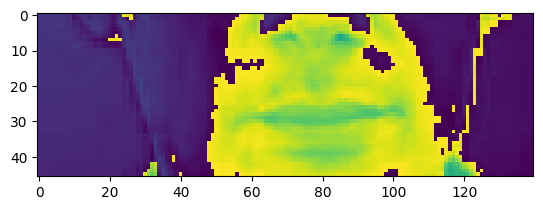

In [64]:
plt.imshow(frames[0])

In [65]:
tf.strings.reduce_join([bytes.decode(x) for x in num_to_char(alignments.numpy()).numpy()])

<tf.Tensor: shape=(), dtype=string, numpy=b'bin blue at f two now'>

In [66]:
def mappable_function(path:str) -> List[str]:
    result = tf.py_function(load_data, [path], ((tf.float32, tf.int64)))
    return result

Create data Pipeline

In [67]:
data = tf.data.Dataset.list_files('./data/s1/*.mpg')
data = data.shuffle(500, reshuffle_each_iteration=False)
data = data.map(mappable_function)
data = data.padded_batch(2, padded_shapes=([75,None,None,None],[40]))
data = data.prefetch(tf.data.AUTOTUNE)

#Added to split
train = data.take(450)
test = data.skip(450)

In [68]:
frames, alignments = data.as_numpy_iterator().next()

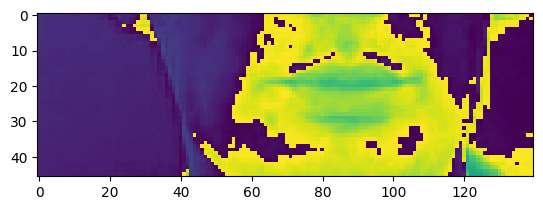

In [69]:
plt.imshow(frames[0,30])

In [70]:
sample = data.as_numpy_iterator()

In [71]:
val = sample.next()
val[0]

array([[[[[ 1.4167988 ],
          [ 1.4167988 ],
          [ 1.4167988 ],
          ...,
          [10.584321  ],
          [ 0.        ],
          [ 0.        ]],

         [[ 1.4167988 ],
          [ 1.4167988 ],
          [ 1.4167988 ],
          ...,
          [10.584321  ],
          [ 0.        ],
          [ 0.        ]],

         [[ 1.2917871 ],
          [ 1.2917871 ],
          [ 1.3334577 ],
          ...,
          [10.625992  ],
          [10.625992  ],
          [10.625992  ]],

         ...,

         [[ 0.9167522 ],
          [ 0.9167522 ],
          [ 0.87508166],
          ...,
          [10.334297  ],
          [10.334297  ],
          [10.334297  ]],

         [[ 0.9167522 ],
          [ 0.9167522 ],
          [ 0.87508166],
          ...,
          [10.334297  ],
          [10.334297  ],
          [10.334297  ]],

         [[ 0.9167522 ],
          [ 0.9167522 ],
          [ 0.87508166],
          ...,
          [10.334297  ],
          [10.334297  ],
          

In [72]:
#Preprocess video

frames = val[0][1]

# Preprocess: float32 → uint8 and ensure RGB
frames = [np.clip(frame * 255, 0, 255).astype(np.uint8) for frame in frames]
frames = [np.repeat(f, 3, axis=2) if f.ndim == 3 and f.shape[2] == 1 else f for f in frames]

imageio.mimsave('./animation.gif', frames, fps = 10)

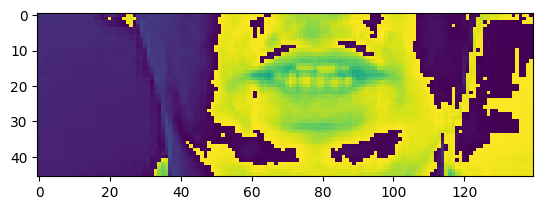

In [73]:
#0:Vidoes, 0:1st video of the batch, 0:return the frame in the video
plt.imshow(val[0][0][50])

In [74]:
#Preprocess alignments

tf.strings.reduce_join([num_to_char(word) for word in val[1][0]])

<tf.Tensor: shape=(), dtype=string, numpy=b'place red with q five again'>

Neural Network

In [75]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv3D, LSTM, Dense,GlobalAveragePooling2D, MaxPooling3D, Dropout, Bidirectional, Activation, Reshape, SpatialDropout3D, BatchNormalization, TimeDistributed, Flatten
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ModelCheckpoint, LearningRateScheduler

In [76]:
data.as_numpy_iterator().next()[0][0].shape #Input to the Neural Network

(75, 46, 140, 1)

In [77]:
model = Sequential()

model.add(Conv3D(128, 3, input_shape=(75,46,140,1), padding='same'))
model.add(Activation('relu'))
model.add(MaxPooling3D((1,2,2)))

model.add(Conv3D(256, 3, padding='same'))
model.add(Activation('relu'))
model.add(MaxPooling3D((1,2,2)))

model.add(Conv3D(75, 3, padding='same'), Activation('relu'))
model.add(MaxPooling3D((1,2,2)))

model.add(TimeDistributed(GlobalAveragePooling2D()))

model.add(Bidirectional(LSTM(128, kernel_initializer='Orthogonal', return_sequences=True)))
model.add(Dropout(.5))

model.add(Bidirectional(LSTM(128, kernel_initializer='Orthogonal', return_sequences=True)))
model.add(Dropout(.5))

model.add(Dense(char_to_num.vocabulary_size()+1, kernel_initializer='he_normal', activation='softmax'))

c:\Users\Win\anaconda3\envs\project\lib\site-packages\keras\src\layers\convolutional\base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [78]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv3d_3 (Conv3D)               │ (None, 75, 46, 140,    │         3,584 │
│                                 │ 128)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 75, 46, 140,    │             0 │
│                                 │ 128)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d_3 (MaxPooling3D)  │ (None, 75, 23, 70,     │             0 │
│                                 │ 128)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_4 (Conv3D)               │ (None, 75, 23, 70,     │       884,992 │
│                                 │ 256)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 75, 23, 70,     │             0 │
│                                 │ 256)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d_4 (MaxPooling3D)  │ (None, 75, 11, 35,     │             0 │
│                                 │ 256)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_5 (Conv3D)               │ (None, 75, 11, 35, 75) │       518,475 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d_5 (MaxPooling3D)  │ (None, 75, 5, 17, 75)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_1              │ (None, 75, 75)         │             0 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_2 (Bidirectional) │ (None, 75, 256)        │       208,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 75, 256)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_3 (Bidirectional) │ (None, 75, 256)        │       394,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 75, 256)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 75, 41)         │        10,537 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,020,724 (7.71 MB)

 Trainable params: 2,020,724 (7.71 MB)

 Non-trainable params: 0 (0.00 B)

In [79]:
yhat = model.predict(val[0])

1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step


In [80]:
tf.argmax(yhat[0], axis=1)

<tf.Tensor: shape=(75,), dtype=int64, numpy=
array([29, 17, 17, 29, 29, 29, 29, 29, 29, 29, 29, 29, 29, 29, 29, 29, 29,
       29, 29, 29, 29, 29, 29, 29, 29, 29, 29, 29, 29, 29, 29, 29, 29, 29,
       29, 29, 29, 29, 29, 29, 29, 29, 29, 29, 29, 29, 29, 29, 29, 29, 29,
       29, 29, 29, 29, 29, 29, 29, 29, 29, 29, 29, 29, 29, 29, 29, 29, 29,
       29, 29, 29, 29, 29, 29, 29])>

In [81]:
tf.strings.reduce_join([num_to_char(tf.argmax(x)) for x in yhat[1]])

<tf.Tensor: shape=(), dtype=string, numpy=b'qqqqq!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!'>

In [82]:
model.input_shape

(None, 75, 46, 140, 1)

In [83]:
model.output_shape

(None, 75, 41)

Training Model

In [84]:
def schedular(epoch, lr):
    if epoch < 30:
        return lr
    else:
        return lr * tf.math.exp(-0.1)

In [85]:
def CTCLoss(y_true, y_pred):
    batch_len = tf.cast(tf.shape(y_true)[0], dtype="int64")
    input_length = tf.cast(tf.shape(y_pred)[1], dtype="int64")
    label_length = tf.cast(tf.shape(y_true)[1], dtype="int64")

    input_length = input_length * tf.ones(shape=(batch_len, 1), dtype="int64")
    label_length = label_length * tf.ones(shape=(batch_len, 1), dtype="int64")

    loss = tf.keras.backend.ctc_batch_cost(y_true, y_pred, input_length, label_length)
    return loss

In [86]:
class ProduceExample(tf.keras.callbacks.Callback):
    def __init__(self, dataset) -> None:
        self.dataset = dataset.as_numpy_iterator()

    def on_epcoh_end(self, epoch, logs=None) -> None:
        data = self.dataset.next()
        yhat = model.predict(data[0])
        decoded = tf.keras.backend.ctc_decode(yhat, [75,75], greedy=False)[0]

        for x in range(len(yhat)):
            print("Original : ", tf.string.reduce_join(num_to_char(data[1][x])).numpy().decode('utf-8'))
            print('Prediction:', tf.strings.reduce_join(num_to_char(decoded[x])).numpy().decode('utf-8'))
            print('~'*100)

In [87]:
model.compile(optimizer=Adam(learning_rate=0.0001), loss=CTCLoss)

In [88]:
checkpoint_callback = ModelCheckpoint(os.path.join('models','checkpoint.weights.h5'), monitor='loss', save_weights_only=True) 

In [89]:
schedule_callback = LearningRateScheduler(schedular)

In [90]:
example_callbacks = ProduceExample(data)

In [41]:
model.fit(train,validation_data=test, epochs=100, callbacks = [checkpoint_callback, schedule_callback, example_callbacks])

Epoch 1/100



KeyboardInterrupt: 

Prediction

In [41]:
import zipfile

url = 'https://drive.google.com/uc?id=1vWscXs4Vt0a_1IH1-ct2TCgXAZT-N3_Y'
output = 'checkpoints.zip'
gdown.download(url, output, quiet=False)

# Extract
with zipfile.ZipFile(output, 'r') as zip_ref:
    zip_ref.extractall('models')

# Check contents
print("Files extracted:", os.listdir('models'))

KeyboardInterrupt: 

In [91]:
model.load_weights('models/checkpoint.weights.h5')  # No .index or .data extension

c:\Users\Win\anaconda3\envs\project\lib\site-packages\keras\src\saving\saving_lib.py:757: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 42 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


In [92]:
test_data = test.as_numpy_iterator()

In [93]:
sample = test_data.next()

In [95]:
yhat = model.predict(sample[0])

1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step


In [96]:
decoded = tf.keras.backend.ctc_decode(yhat, input_length=[75,75], greedy=True)

In [97]:
print('~'*100, 'PREDICTION')
[tf.strings.reduce_join([num_to_char(word) for word in sentence]) for sentence in decoded]

~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~ PREDICTION


[<tf.Tensor: shape=(), dtype=string, numpy=b'la e ola e o'>,
 <tf.Tensor: shape=(), dtype=string, numpy=b''>]

In [98]:
print('~'*100, 'REAL TEXT')
[tf.strings.reduce_join([num_to_char(word) for word in sentence]) for sentence in [sample[1]]]

~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~ REAL TEXT


[<tf.Tensor: shape=(), dtype=string, numpy=b'bin red by a zero pleasebin white by n five again'>]